In [23]:
#先加载数据
!pip install mysql-connector-python

import mysql.connector
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt #一般用来画图，调画图函数
import matplotlib #一般用来做全局配置



Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
import warnings
warnings.filterwarnings('ignore') #忽略警告信息
import os
plt.rcParams['font.sans-serif']=['SimHei','Microsoft YaHei','KaiTi']
plt.rcParams['axes.unicode_minus']=False
import getpass


In [25]:

conn=mysql.connector.connect(
    host='localhost',
    user='root',
    password=getpass.getpass('请输入MySQL密码：'),
    database='taobao_analysis'
)
conn

In [26]:
def query(sql):
    return pd.read_sql(sql,conn)  #去conn这个数据库查你要执行的sql语句,返回一个pandas的DataFrame表格


In [27]:
os.makedirs('output',exist_ok=True) #os可以操作系统和文件夹,makedirs创建文件夹,'output'要创建的名字,exist_ok=True已经存在也没有关系

In [28]:
ov=query('select * from overview_stats').iloc[0] #提取overview_stats这个表的第0行
print(f"大盘：总行为 {ov['total_rows']:,}|uv {ov['total_uv']:,}|pv {ov['total_pv']:,}|购买 {ov['total_buy']:,}|购买用户 {ov['buy_users']:,}")



大盘：总行为 100,095,182.0|uv 987,991.0|pv 89,660,671.0|购买 2,015,807.0|购买用户 672,404.0


In [29]:
beh=query('select * from behavior_stats order by pct desc')
beh['行为类型']=beh['behavior_type'].map({'pv':'浏览','cart':'加购','fav':'收藏','buy':'购买'})
beh[['行为类型','cnt','pct']].rename(columns={'cnt':'次数','pct':'占比'})


,行为类型,次数,占比
0,浏览,89660671,89.58
1,加购,5530446,5.53
2,收藏,2888258,2.89
3,购买,2015807,2.01


非主路径成交人数72126 | 总购买人数672404
浏览→意向 86.93% | 意向→购买 70.17% | 总转化 61.00% | 非主路径成交转化10.73%


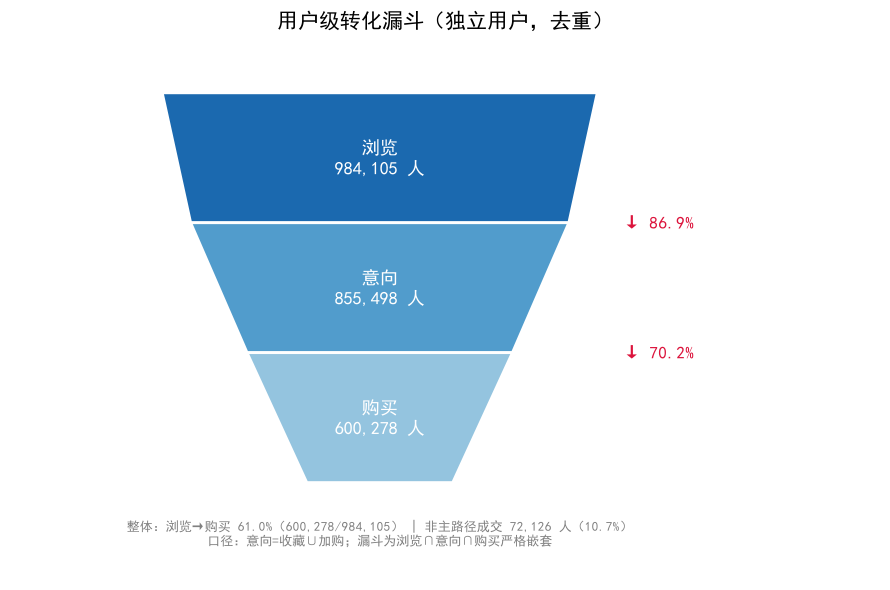

In [30]:

plt.close()  # 先关掉饼图画布，避免叠加
from matplotlib.patches import Polygon  # 导入梯形补丁，用来画漏斗每一层

funnel = query('select * from user_funnel_stats')
r = funnel.iloc[0]
浏览 = int(r['浏览人数'])
意向 = int(r['浏览意向人数（收藏或加购）'])
购买 = int(r['浏览意向购买人数'])
总购买人数 = int(r['总购买人数'])
非主路径成交人数 = (int(r['无浏览无意向购买人数']) + int(r['无浏览有意向购买人数'])
                 + int(r['无意向购买人数']))
print(f'非主路径成交人数{非主路径成交人数} | 总购买人数{总购买人数}')
print(f"浏览→意向 {意向/浏览*100:.2f}% | 意向→购买 {购买/意向*100:.2f}% | 总转化 {购买/浏览*100:.2f}% | 非主路径成交转化{非主路径成交人数/总购买人数*100:.2f}%")

stages = ['浏览', '意向', '购买']
values = [浏览, 意向, 购买]
n = len(stages)
max_v = max(values)
widths = [v / max_v for v in values]  # 每层宽度按人数比例，形成漏斗形

fig, ax = plt.subplots(figsize=(9, 6))
colors = plt.cm.Blues([0.78, 0.58, 0.40])  # 蓝色由深到浅

for i, (stage, v) in enumerate(zip(stages, values)):  #zip把(stages, values)配对打包，enumerate把每对从0开始编号
    y_top = n - i          # 该层上边缘的 y 坐标
    y_bot = y_top - 1      # 该层下边缘的 y 坐标
    top_w = widths[i]      # 上边宽度
    bot_w = widths[i + 1] if i < n - 1 else widths[i] * 0.55   # 最底层下边收窄到本层宽度的 55%，形成尖底
    ax.add_patch(Polygon(
        [[-top_w/2, y_top], [top_w/2, y_top],
         [bot_w/2, y_bot], [-bot_w/2, y_bot]],
        closed=True, facecolor=colors[i], edgecolor='white', linewidth=2))  #closed=True把最后一个点连回第一个点，形成封闭图形；
    #edgecolor='white'边线白色，linewidth=2边线粗 2
    ax.text(0, (y_top + y_bot)/2, f'{stage}\n{v:,} 人',
            ha='center', va='center', fontsize=13, color='white', fontweight='bold')  #ha='center'水平居中, va='center'垂直居中

# 层间转化率：红色小字，标在梯形右侧
for i in range(n - 1):
    rate = values[i + 1] / values[i]
    ax.text(0.56, n - i - 1, f'↓ {rate*100:.1f}%',
            ha='left', va='center', fontsize=12, color='crimson', fontweight='bold')

ax.set_title('用户级转化漏斗（独立用户，去重）', fontsize=15, pad=14)  #pad=14标题和图之间的间距
ax.text(0, -0.28,
        f'整体：浏览→购买 {购买/浏览*100:.1f}%（{购买:,}/{浏览:,}）'
        f' | 非主路径成交 {非主路径成交人数:,} 人（{非主路径成交人数/总购买人数*100:.1f}%）'
        '\n口径：意向=收藏∪加购；漏斗为浏览∩意向∩购买严格嵌套',
        ha='center', va='top', fontsize=9, color='gray')

ax.set_xlim(-0.85, 1.15)
ax.set_ylim(-0.75, n + 0.35)
ax.axis('off')  # 隐藏坐标轴
fig.tight_layout()
plt.savefig('funnel_users.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()  # notebook 里直接显示



**口径说明：为什么不是“浏览→收藏→加购→购买”四层漏斗**
收藏和加购是同级行为，并不是先后行为，故本漏斗的结构为： 浏览→意向（收藏∪加购）→购买

**关于非主路径成交 72,126 名（ 10.7%）用户**
非主路径成交用户指的是有购买行为，但未经过“浏览→意向（收藏∪加购）→购买”完整链条的用户，其中包括：
没有浏览没有意向直接购买的 109 名用户+没有浏览但是有意向直接购买的 2,985 名用户+浏览但是没有意向直接购买的 69,032 名用户 = 72,126 名用户

In [31]:
seg=query('''select case when cart_cnt>0 and fav_cnt>0 then '加购且收藏' 
                        when cart_cnt>0 then '仅加购'
                        else '仅收藏'
                     end 用户意向,
                     sum(buy_cnt>0) 购买者,
                     sum(buy_cnt=0) 未购买者,
                     count(*) 合计,
                    ROUND(SUM(buy_cnt > 0) / COUNT(*) * 100, 2) AS 购买占比,
                    ROUND(SUM(buy_cnt= 0) / COUNT(*) * 100, 2) AS 未购买占比
            from user_stats
            where pv_cnt>0 and (fav_cnt>0 or cart_cnt>0)
            group by 用户意向
            order by 购买占比 desc
        ''')
display(seg)

,用户意向,购买者,未购买者,合计,购买占比,未购买占比
0,加购且收藏,203606.0,64117.0,267723,76.05,23.95
1,仅加购,324802.0,143149.0,467951,69.41,30.59
2,仅收藏,71870.0,47954.0,119824,59.98,40.02


见上表可知：加购且收藏的购买占比 76.05 > 仅加购的购买占比 69.41 > 仅收藏的购买占比 59.98
可以发现：意向信号越强，购买占比越高

结论：984,105 名浏览的用户中仅流失128,607名（13.1%）用户，但是855,498 名 "浏览且形成意向" 的用户中流失255,220 人（29.8%），故 “意向（收藏∪加购）→ 购买” 是流失最严重的环节。

表明：针对意向信号越强，购买占比越高这一分析结果，加购且收藏未购买用户（64117 名）+仅加购未购买用户（143149 名）=207,266 名用户是精准运营的核心对象，可定向发放优惠券；仅收藏未购买用户（47954 名）运营应该及时推送商品核心卖点与降价 / 库存提醒。

测算显示：意向→购买转化率每提升 1 个百分点可新增约 8,555 名（855,498 × 1% = 8,554.98 ≈ 8,555 名）购买用户。

需注意：另有 72,126 名用户是通过非主路径购买的，这部分人不在漏斗分析图中体现。

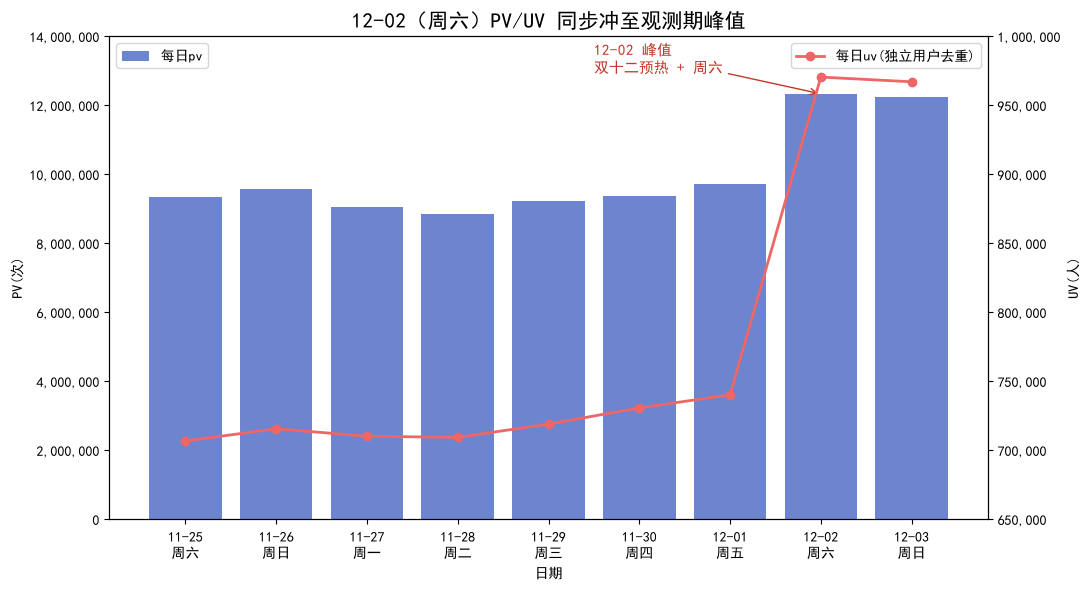

日期: 12-02 PV: 12,329,641.0 , UV: 970,401
日期: 12-03 PV: 12,237,300.0 , UV: 966,977
较平稳期均值：PV +32.6%，UV +35.0%


In [32]:
plt.close()
from matplotlib.ticker import FuncFormatter
daily=query('select date_time,total_pv,uv from daily_stats order by date_time asc')
wk = ['周一', '周二', '周三', '周四', '周五', '周六', '周日']
labels = [f"{d.strftime('%m-%d')}\n{wk[d.weekday()]}" for d in pd.to_datetime(daily['date_time'])]
daily['日期']=daily['date_time'].astype(str).str[5:]  #只要月日
def fmt_thousands(x,pos):
    return f'{x:,.0f}'
fig, ax1=plt.subplots(figsize=(11,6))
ax1.bar(daily['日期'],daily['total_pv'],color='#5470c6',alpha=0.85,label='每日pv')
ax1.set_xticks(range(len(labels)))
ax1.set_xticklabels(labels)
ax1.set_ylabel('PV(次)')
ax1.yaxis.set_major_formatter(FuncFormatter(fmt_thousands))
ax1.set_ylim(0, 14000000)
ax1.legend(loc='upper left')
ax1.set_xlabel('日期')

ax2=ax1.twinx()
ax2.plot(daily['日期'],daily['uv'],color='#ee6666',marker='o',markersize=6,linewidth=2,label='每日uv(独立用户去重)')
ax2.set_ylabel('UV(人)')
ax2.yaxis.set_major_formatter(FuncFormatter(fmt_thousands))
ax2.set_ylim(650000, 1000000)
ax2.legend(loc='upper right')
ax1.set_title('12-02（周六）PV/UV 同步冲至观测期峰值',fontsize=15)
peak_i = daily['total_pv'].idxmax()
ax1.annotate('12-02 峰值\n双十二预热 + 周六',
             xy=(peak_i, daily.loc[peak_i, 'total_pv']),
             xytext=(peak_i - 2.5, daily['total_pv'].max() * 1.05),
             fontsize=11, color='#c0392b',
             arrowprops=dict(arrowstyle='->', color='#c0392b'))
fig.tight_layout()
plt.savefig('daily_pv_uv.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

p, prev = daily.loc[peak_i], daily.loc[peak_i - 1]
p1=daily.loc[peak_i+1]
base_pv = daily.loc[:peak_i-1, 'total_pv'].mean()   # 11-25~12-01 均值
base_uv = daily.loc[:peak_i-1, 'uv'].mean()
print(f"日期: {p['日期']} PV: {p['total_pv']:,} , UV: {p['uv']:,}\n日期: {p1['日期']} PV: {p1['total_pv']:,} , UV: {p1['uv']:,}")
print(f"较平稳期均值：PV +{(p['total_pv']/base_pv-1)*100:.1f}%，UV +{(p['uv']/base_uv-1)*100:.1f}%")


结论：11-25~12-01每日PV和每日UV较平稳，在12-02这天冲至峰值，PV: 12,329,641 , UV: 970,401 较前7日均值分别上涨32.6%,35.0%；12-03日这天PV和UV仍维持高位（PV 12,237,300、UV 966,977），呈"预热平台期"而非单日脉冲。

业务含义：12—02日平台预热活动开始加上恰逢周六（时间吻合；归因为假设，可结合营销日历佐证），pv和uv同步达到峰值，且 UV 与 PV 同向上涨说明并非
单一指标异常。建议运营在此窗口（12-02~12-03）加大内容种草和领券指导；具体触达时段依据小时活跃分布确定（见下节分析）。

口径：按北京时间（timestamp +8h）归日；PV = 当日浏览次数，UV = 当日去重活跃用户数；涨幅基准为11-25~12-01七日均值。

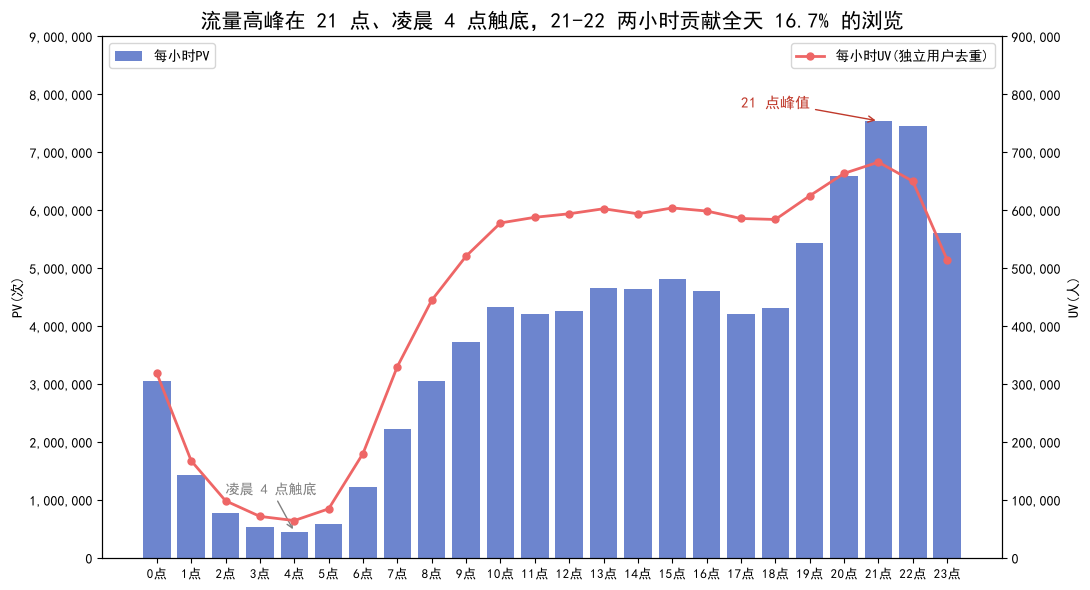

峰值时间: 21点 PV: 7538382 UV: 682751
触底时间: 4点 PV: 449628 UV: 64213
最大两小时窗口: 21.0-22.0 点, 合计 PV = 14,981,451 , 占全天 16.7%


In [33]:
plt.close()
hourly=query('select hour_time,pv total_pv,uv from hourly_stats order by hour_time asc')
def fmt_thousands(x,pos):
    return f'{x:,.0f}'
fig, ax1=plt.subplots(figsize=(11,6))
ax1.bar(hourly['hour_time'],hourly['total_pv'],color='#5470c6',alpha=0.85,label='每小时PV')
ax1.set_xticks(range(24))
ax1.set_xticklabels([f'{h}点' for h in range(24)], fontsize=9)
ax1.set_ylabel('PV(次)')
ax1.yaxis.set_major_formatter(FuncFormatter(fmt_thousands))
ax1.set_ylim(0,9000000)
ax1.legend(loc='upper left')
ax1.set_title('小时')
ax2=ax1.twinx()
ax2.plot(hourly['hour_time'],hourly['uv'],color='#ee6666',marker='o',markersize=5,linewidth=2,label='每小时UV(独立用户去重)')
ax2.set_ylabel('UV(人)')
ax2.yaxis.set_major_formatter(FuncFormatter(fmt_thousands))
peak_i = hourly['total_pv'].idxmax()
ax1.annotate('21 点峰值',
             xy=(peak_i, hourly.loc[peak_i, 'total_pv']),
             xytext=(peak_i - 4, hourly['total_pv'].max() * 1.03),
             fontsize=11, color='#c0392b',
             arrowprops=dict(arrowstyle='->', color='#c0392b'))
trough_i = hourly['total_pv'].idxmin()    
ax1.annotate('凌晨 4 点触底',
             xy=(trough_i, hourly.loc[trough_i, 'total_pv']),
             xytext=(trough_i - 2,hourly['total_pv'].min() * 2.45),
             fontsize=10, color='gray',
             arrowprops=dict(arrowstyle='->', color='gray'))

ax2.set_ylim(0,900000)
ax2.legend(loc='upper right')
ax1.set_title('流量高峰在 21 点、凌晨 4 点触底，21-22 两小时贡献全天 16.7% 的浏览',fontsize=15)
fig.tight_layout()
plt.savefig('hourly_pv_uv.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

p, p1, l = hourly.loc[peak_i], hourly.loc[peak_i + 1], hourly.loc[trough_i]
print(f"峰值时间: {int(p['hour_time'])}点 PV: {int(p['total_pv'])} UV: {int(p['uv'])}\n触底时间: {int(l['hour_time'])}点 PV: {int(l['total_pv'])} UV: {int(l['uv'])}")
print(f"最大两小时窗口: {p['hour_time']}-{p1['hour_time']} 点, 合计 PV = {(p['total_pv']+p1['total_pv']):,.0f} , 占全天 {(p['total_pv']+p1['total_pv'])*100/hourly['total_pv'].sum():.1f}%")


结论：可以看出0点后每小时pv/uv逐步下降，在4点（PV: 449628, UV: 64213）触底后逐步回升，10-18点保持稳定，19点起持续走高，21点（PV: 7538382, UV: 682751）达到峰值，最大两小时窗口: 21.0-22.0 点, 合计 PV = 14,981,451 , 贡献全天浏览量的 16.7%。

业务含义：20~22点是触达黄金窗口，适合集中投放内容种草、推送活动通知与领券指导,19-23 时宜安排客服与直播主力时段,0-6 时活跃极低，不安排运营动作，避免打扰与资源浪费。

口径：PV = 当日浏览次数，UV = 当日去重活跃用户数，占比分母为观测期全部浏览量（不含收藏/加购/购买行为），数据为 2017-11-25 至 12-03 九天聚合结果。

In [34]:
flow=query('select item_id,pv_cnt,buy_cnt from item_stats order by pv_cnt desc limit 10')
buy=query('select item_id,pv_cnt,buy_cnt from item_stats order by buy_cnt desc limit 10')
print('流量TOP10:\n',flow.to_string(index=False))
print('购买TOP10:\n',buy.to_string(index=False))
overlap=set(flow['item_id'])&set(buy['item_id'])
print('两个榜单重叠商品为:',overlap)

流量TOP10:
  item_id  pv_cnt  buy_cnt
  812879 30079.0    136.0
 3845720 25650.0    105.0
  138964 21103.0     95.0
 2331370 19482.0    163.0
 2032668 19141.0     57.0
 1535294 17840.0    402.0
   59883 17404.0     39.0
 4211339 17349.0     65.0
 3031354 17169.0    950.0
 3371523 17159.0      7.0
购买TOP10:
  item_id  pv_cnt  buy_cnt
 3122135  1779.0   1408.0
 3031354 17169.0    950.0
 3964583  5018.0    675.0
 2560262 10388.0    665.0
 2964774  6579.0    629.0
  740947  7738.0    560.0
 1910706  1645.0    548.0
 1116492   898.0    512.0
  705557  9308.0    497.0
 4443059 14082.0    493.0
两个榜单重叠商品为: {3031354}


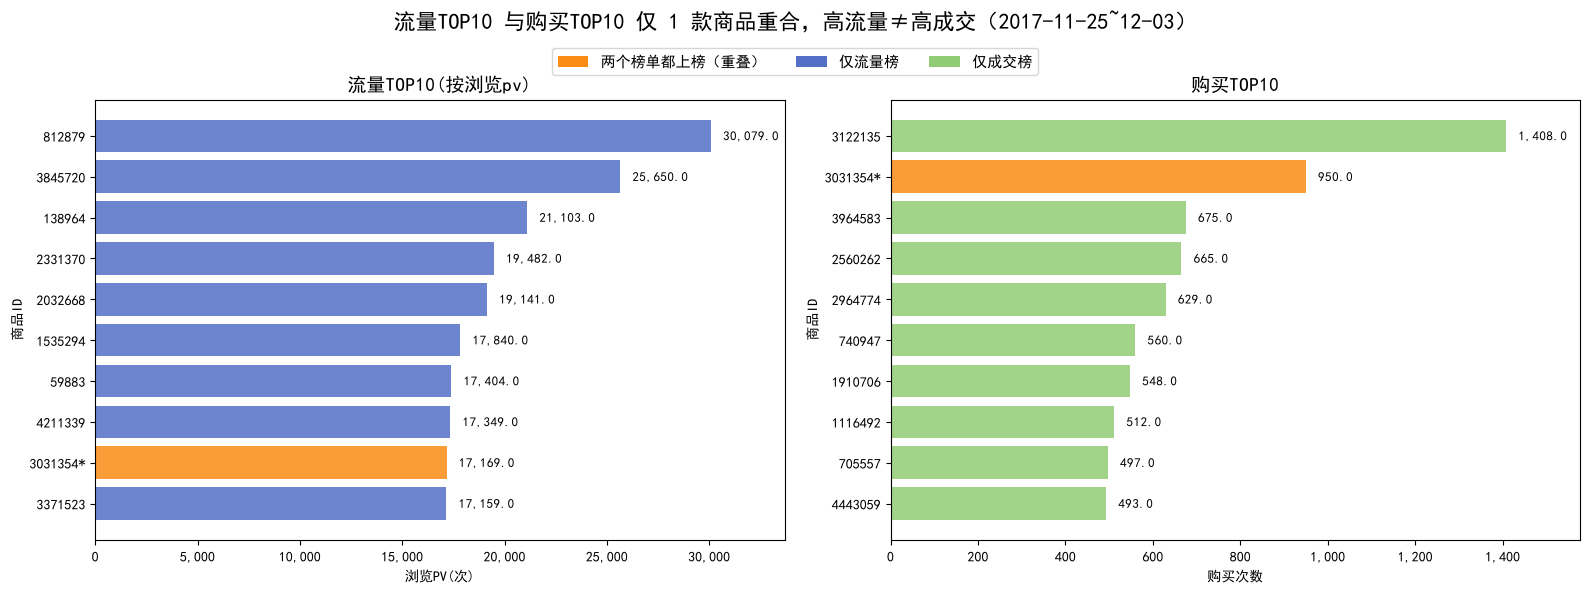

In [35]:
from matplotlib.patches import Patch  #画图例色块
def fmt_thousands(x,pos):
    return f'{x:,.0f}'
fig,axes=plt.subplots(1,2,figsize=(16,6))
#为了特别显示出两个榜单均上榜的商品ID
flow_colors=['#fa8c16' if i in overlap else '#5470c6' for i in flow['item_id']]
buy_colors=['#fa8c16' if i in overlap else '#91cc75' for i in buy['item_id']]
flow_labels=[f'{i}*' if i in overlap else str(i) for i in flow['item_id']]
buy_labels=[f'{i}*' if i in overlap else str(i) for i in buy['item_id']]
axes[0].barh(flow_labels,flow['pv_cnt'],color=flow_colors,alpha=0.85)
axes[0].invert_yaxis()
axes[0].set_xlabel('浏览PV(次)')
axes[0].set_ylabel('商品ID')
axes[0].xaxis.set_major_formatter(FuncFormatter(fmt_thousands))
axes[0].set_title('流量TOP10(按浏览pv)',fontsize=14)
for i,v in enumerate(flow['pv_cnt']):
    axes[0].text(v+flow['pv_cnt'].max()*0.02,i,f'{v:,}',va='center',fontsize=9) #给每个横着的数据条加上具体的数字
axes[0].set_xlim(0, flow['pv_cnt'].max() * 1.12)

axes[1].barh(buy_labels,buy['buy_cnt'],color=buy_colors,alpha=0.85)
axes[1].invert_yaxis()
axes[1].set_xlabel('购买次数')
axes[1].set_ylabel('商品ID')
axes[1].xaxis.set_major_formatter(FuncFormatter(fmt_thousands))
axes[1].set_title('购买TOP10',fontsize=14)
for i,v in enumerate(buy['buy_cnt']):
    axes[1].text(v+buy['buy_cnt'].max()*0.02,i,f'{v:,}',va='center',fontsize=9)
axes[1].set_xlim(0, buy['buy_cnt'].max() * 1.12)
legend_handles = [Patch(facecolor='#fa8c16', label='两个榜单都上榜（重叠）'),
                  Patch(facecolor='#5470c6', label='仅流量榜'),
                  Patch(facecolor='#91cc75', label='仅成交榜')]
fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, 0.93),
           ncol=3, fontsize=11)  #loc='upper center'上方居中，bbox_to_anchor=(0.5, 0.93)具体细调位置(x,y)是相对于画布的大小，0.5是居中，0.93
#是距画布底部大约93%， ncol=3三个图例色块横着排， ncol=1则是竖着排
fig.suptitle('流量TOP10 与购买TOP10 仅 1 款商品重合，高流量≠高成交（2017-11-25~12-03）',fontsize=16)
fig.tight_layout(rect=[0,0,1,0.96])
plt.savefig('top10_compare.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

In [36]:
f1_id, f1=flow['item_id'].iloc[0], flow['pv_cnt'].iloc[0]
f2_id, f2=flow['item_id'].iloc[1], flow['pv_cnt'].iloc[1]
print(f'流量榜：第1名({f1_id}){f1:,}次 vs 第2名({f2_id}){f2:,}次，高出{f1/f2*100-100:.1f}%')
f4_id, f4=flow['item_id'].iloc[3], flow['pv_cnt'].iloc[3]
f10_id, f10=flow['item_id'].iloc[9], flow['pv_cnt'].iloc[9]
print(f'流量榜：第4名({f4_id}){f4:,}次 vs 第2名({f10_id}){f10:,}次，高出{f4/f10*100-100:.1f}%(差距越来越小)')
b1_id, b1=buy['item_id'].iloc[0], buy['buy_cnt'].iloc[0]
b2_id, b2=buy['item_id'].iloc[1], buy['buy_cnt'].iloc[1]
print(f'购买榜：第1名({b1_id}){b1:,}次 vs 第2名({b2_id}){b2:,}次，高出{b1/b2*100-100:.1f}%')
print(overlap,'：流量榜第9名，成交榜第 2 名')

流量榜：第1名(812879)30,079.0次 vs 第2名(3845720)25,650.0次，高出17.3%
流量榜：第4名(2331370)19,482.0次 vs 第2名(3371523)17,159.0次，高出13.5%(差距越来越小)
购买榜：第1名(3122135)1,408.0次 vs 第2名(3031354)950.0次，高出48.2%
{3031354} ：流量榜第9名，成交榜第 2 名


结论：流量TOP10表的第一名（商品ID：812879，PV：30,079），第二名（商品ID：3845720，PV：25,650）和购买TOP10表的第一名（商品ID：3122135，PV：1,408），第二名（商品ID：3031354，PV：950）头部断层均明显，且购买TOP10表断层更明显（第1名高出第2名 48.2%，流量TOP10表为 17.3% ）；两个榜单仅有一个商品（商品ID：3031354）重叠，流量榜冠军未进购买榜，购买榜冠军未进流量榜。

业务含义：高流量与高成交错位，说明流量投放未转化为成交。对于商品ID：812879，运营应核查详情页说服力与价格竞争力、压缩无效曝光；对于商品ID：3122135，应加大推荐位与搜索卡位；对于商品ID：3031354 是唯一两个榜单都上榜的商品可将其运营打法作为标杆复用。高流量商品究竟是弱在加购还是购买环节？下一张图按“浏览→加购”与“加购→购买”两率对照全量基准拆解。

In [37]:
flow_buy=query('select item_id,浏览到加购率,加购到购买率 from flow_buy_stats')
print(flow_buy.to_string(index=False))
cart_rate = ov['total_cart'] / ov['total_pv'] * 100   # 浏览→加购：加购行为数 ÷ 浏览行为数
buy_rate  = ov['total_buy'] / ov['total_cart'] * 100  # 加购→购买：购买行为数 ÷ 加购行为数
fav_rate  = ov['total_fav'] / ov['total_pv'] * 100   # 浏览→收藏（顺带算，报告备用）
print(f"全量基准：浏览→加购 {cart_rate:.2f}% | 加购→购买 {buy_rate:.2f}% | 浏览→收藏 {fav_rate:.2f}%")


 item_id  浏览到加购率  加购到购买率
  812879    5.08    8.90
 3845720    3.32   12.34
  138964    5.37    8.38
 2331370    7.77   10.77
 2032668    2.70   11.03
 1535294    6.24   36.09
   59883    2.10   10.66
 4211339    4.97    7.53
 3031354   10.26   53.95
 3371523    0.29   14.00
全量基准：浏览→加购 6.17% | 加购→购买 36.45% | 浏览→收藏 3.22%


In [38]:
# %%
# 自动分类：把 10 个商品按两率 vs 全量基准 分成 4 类
# cart_rate=6.17（浏览→加购基准）buy_rate=36.45（加购→购买基准），已在上一个 cell 算好

def 分类(row):
    if row['浏览到加购率'] >= cart_rate and row['加购到购买率'] >= buy_rate:
        return '双高'
    elif row['浏览到加购率'] >= cart_rate and row['加购到购买率'] < buy_rate:
        return '高加购低购买'
    elif row['浏览到加购率'] < cart_rate and row['加购到购买率'] >= buy_rate:
        return '低加购高购买'
    else:
        return '双低'

flow_buy['类型'] = flow_buy.apply(分类, axis=1)   # 按行逐条打标签
flow_buy


,item_id,浏览到加购率,加购到购买率,类型
0,812879,5.08,8.90,双低
1,3845720,3.32,12.34,双低
2,138964,5.37,8.38,双低
3,2331370,7.77,10.77,高加购低购买
4,2032668,2.70,11.03,双低
5,1535294,6.24,36.09,高加购低购买
6,59883,2.10,10.66,双低
7,4211339,4.97,7.53,双低
8,3031354,10.26,53.95,双高
9,3371523,0.29,14.00,双低


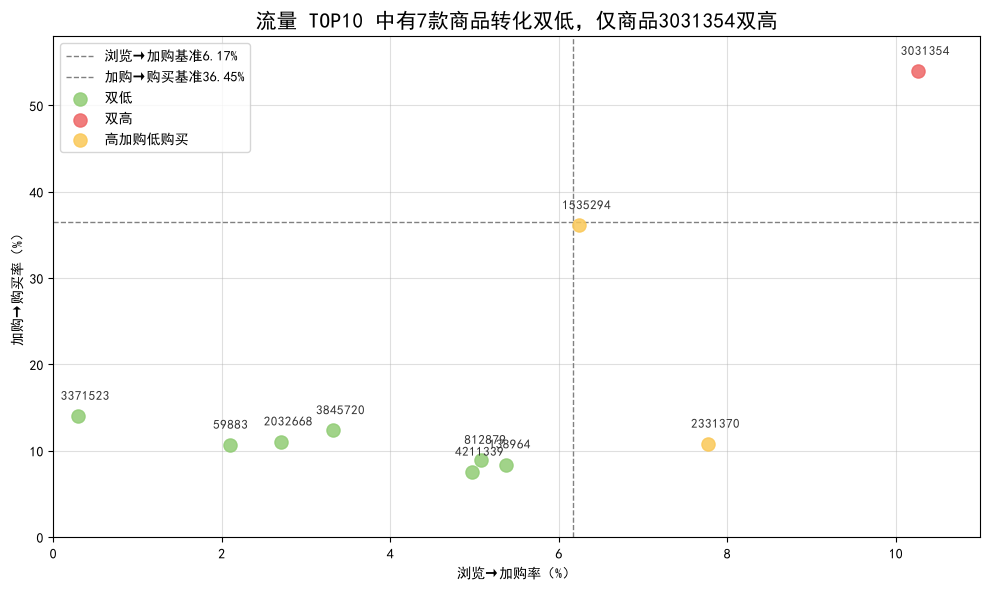

In [39]:

plt.close()
fig, ax=plt.subplots(figsize=(10,6))
colors={
    '双高':'#ee6666','高加购低购买':'#fac858','低加购高购买':'#5470c6','双低':'#91cc75'
}
ax.axvline(cart_rate,color='gray',linestyle='--',linewidth=1,label=f'浏览→加购基准{cart_rate:.2f}%')  #x轴
ax.axhline(buy_rate,color='gray',linestyle='--',linewidth=1,label=f'加购→购买基准{buy_rate:.2f}%')  #y轴
xr=flow_buy['浏览到加购率'].max()-flow_buy['浏览到加购率'].min()
yr=flow_buy['加购到购买率'].max()-flow_buy['加购到购买率'].min()
for q,df in flow_buy.groupby('类型'): #flow_buy.groupby('类型')返回的是每个象限的名字以及对应的每一行的数值
    ax.scatter(df['浏览到加购率'],df['加购到购买率'],color=colors.get(q,'#999999'),alpha=0.85,s=90,label=q,zorder=3) #label=每一个图例叫什么
for _,r in flow_buy.iterrows(): #flow_buy.iterrows()返回的是每一行的行号以及对应的数值，返回的是Series类型
    ax.annotate(int(r['item_id']),(r['浏览到加购率']-xr*0.02,r['加购到购买率']+yr*0.04),fontsize=9,color='#333333',zorder=4)
ax.set_xlabel('浏览→加购率（%）')
ax.set_ylabel('加购→购买率（%）')
ax.set_title('流量 TOP10 中有7款商品转化双低，仅商品3031354双高', fontsize=15)
ax.set_xlim(0, 11)
ax.set_ylim(0, 58)
ax.legend(loc='upper left')
ax.grid(alpha=0.4)
fig.tight_layout()
# 图内标题：流量 TOP10 商品转化四象限（对照全量基准）
plt.savefig('output/top10_conversion_quadrant.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

结论：承接上节————两榜商品仅商品ID:3031354 重叠。按转化两率分型后可见，这种错位的本质是转化能力的差异： 仅商品ID:3031354 唯一流量榜和购买榜均上榜+唯一转化双高，两个独立口径互证，标杆结论仍成立，是明星产品；商品ID:1535294 的两率贴着两条基线，可作参照；商品ID:2331370 加购率7.77%，高于基准6.17%，购买率10.77%，远低于基准36.45%，卡在付款环节；其他7款商品（含流量榜冠军商品ID: 812879）的两率均低于全量基准。

业务含义：商品ID: 812879，虽然曝光度比较大，但是加购率和购买率均低，上节分析的“流量投放未转化为成交”不够准确，浏览→加购环节就已经出现问题，并非单纯成交问题——对该商品应先优化详情页与价格竞争力，再谈投放；商品ID:2331370 购买率低这种情况，运营应对加购的用户及时发放优惠券，推送降价/补货提醒,以及关注竞品动态；其余双低商品应压缩无效流量投放，把位置让给高转化的商品。

口径：基准为全量行为比——总加购÷总浏览 = 6.17%、总购买÷总加购 = 36.45%，基于 2017-11-25~12-03 九天全部行为数据计算；各商品两率口径与基准一致（该商品加购行为数÷浏览行为数、购买行为数÷加购行为数）。

购买用户合计：672,404（应=672,404）
99% 的用户购买次数 ≤ 14 次
99分位 cut=14，长尾（>14次）合并为 '15+'，该区间 5,473 人
购买一次的用户:228,546| 占比：33.99%
复购用户（≥2次）：443,858 | 复购率：66.01% | 购买次数15+用户占比：0.81%


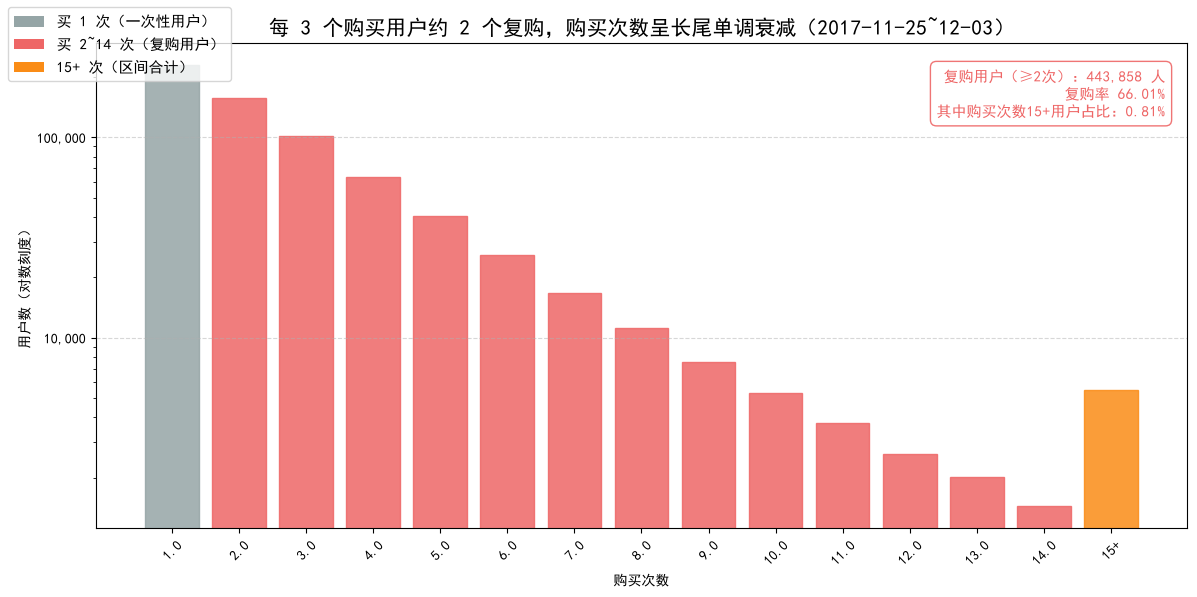

平均购买次数：4.03


In [40]:
plt.close()

rep = query('''
    select buy_cnt, count(*) as users
    from user_stats
    where buy_cnt > 0
    group by buy_cnt
    order by buy_cnt
''')
print(f"购买用户合计：{rep['users'].sum():,}（应=672,404）")
rep_sorted = rep.sort_values('buy_cnt')
rep_sorted['累计用户'] = rep_sorted['users'].cumsum()
rep_sorted['累计占比'] = rep_sorted['累计用户'] / rep_sorted['users'].sum()

# 找到"累计用户占比首次 ≥ 99%"对应的购买次数
cut = int(rep_sorted.loc[rep_sorted['累计占比'] >= 0.99, 'buy_cnt'].iloc[0])
print(f"99% 的用户购买次数 ≤ {cut} 次")

# ★ 长尾合并点由数据自动确定：99 分位（99% 用户购买次数 ≤ cut）
cut = int(rep.loc[rep['users'].cumsum()/rep['users'].sum()>=0.99,'buy_cnt'].iloc[0]) #这里的99分位是用户数的99分位，不是购买次数
主体 = rep[rep['buy_cnt'] <= cut].copy()
尾 = rep[rep['buy_cnt'] > cut]
合并 = pd.DataFrame({'buy_cnt': [f'{cut+1}+'], 'users': [尾['users'].sum()]})
分布 = pd.concat([主体, 合并], ignore_index=True)
print(f"99分位 cut={cut}，长尾（>{cut}次）合并为 '{cut+1}+'，该区间 {尾['users'].sum():,} 人")
# 复购率：购买≥2次 ÷ 全部购买用户
复购人数 = rep[rep['buy_cnt'] >= 2]['users'].sum()
购买用户 = rep['users'].sum()
复购率 = 复购人数 / 购买用户 * 100
长尾占比=合并['users'].iloc[0]/购买用户 * 100
print(f"购买一次的用户:{购买用户-复购人数:,}| 占比：{(购买用户-复购人数)*100/购买用户:.2f}%\n复购用户（≥2次）：{复购人数:,} | 复购率：{复购率:.2f}% | 购买次数{cut+1}+用户占比：{长尾占比:.2f}%")

def fmt_thousands(x, pos):
    return f'{x:,.0f}'

fig, ax = plt.subplots(figsize=(12, 6))
x = range(len(分布))                       # 用数值位置，避免混了字符串的排序问题
bars = ax.bar(x, 分布['users'], color='#5470c6', alpha=0.85)

# 颜色按位置判断：第1根灰(买1次)、最后1根橙(合并区间)、中间红(复购)
colors = ['#95a5a6' if i == 0 else ('#fa8c16' if i == len(分布) - 1 else '#ee6666')
          for i in range(len(分布))]
for bar, c in zip(bars, colors):
    bar.set_color(c)

ax.set_yscale('log')                       # 长尾悬殊，必须对数轴
ax.set_xticks(list(x))
ax.set_xticklabels(分布['buy_cnt'].astype(str), rotation=45)
ax.set_ylabel('用户数（对数刻度）')
ax.yaxis.set_major_formatter(FuncFormatter(fmt_thousands))
ax.set_xlabel('购买次数')
ax.set_title('每 3 个购买用户约 2 个复购，购买次数呈长尾单调衰减（2017-11-25~12-03）', fontsize=15)

# 图例：标签跟着 cut 自动变
fig.legend(handles=[Patch(facecolor='#95a5a6', label='买 1 次（一次性用户）'),
                    Patch(facecolor='#ee6666', label=f'买 2~{cut} 次（复购用户）'),
                    Patch(facecolor='#fa8c16', label=f'{cut+1}+ 次（区间合计）')],
           loc='upper left', fontsize=11)

# 复购率图注
ax.annotate(f'复购用户（≥2次）：{复购人数:,} 人\n复购率 {复购率:.2f}%\n其中购买次数15+用户占比：{长尾占比:.2f}%',
            xy=(0.98, 0.95), xycoords='axes fraction', #xycoords='axes fraction'即坐标用的相对绘图比例
            ha='right', va='top', fontsize=11, color='#ee6666',
            bbox=dict(boxstyle='round,pad=0.4', fc='white', ec='#ee6666', alpha=0.9)) 
#bbox=dict()加一个边框的背景框，boxstyle='round,pad=0.4'，拐角是圆的，文字到边框的距离是0.4

ax.grid(axis='y', linestyle='--', alpha=0.5)
fig.tight_layout()
plt.savefig('repurchase_dist.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print(f"平均购买次数：{(rep[rep['buy_cnt'] >= 2]['buy_cnt']*rep[rep['buy_cnt'] >= 2]['users']).sum()/rep[rep['buy_cnt'] >= 2]['users'].sum():.2f}")

In [41]:
rep2 = rep.copy()
rep2['衰减比'] = rep2['users'] / rep2['users'].shift(1)   # 本级/上一级
print(rep2[['buy_cnt', 'users', '衰减比']].head(14))
print('平均衰减比：',rep2['衰减比'].iloc[1:14].mean())

    buy_cnt   users       衰减比
0       1.0  228546       NaN
1       2.0  157240  0.688002
2       3.0  100933  0.641904
3       4.0   63453  0.628665
4       5.0   40409  0.636834
5       6.0   25726  0.636640
6       7.0   16735  0.650509
7       8.0   11223  0.670630
8       9.0    7583  0.675666
9      10.0    5269  0.694844
10     11.0    3727  0.707345
11     12.0    2627  0.704856
12     13.0    2019  0.768557
13     14.0    1441  0.713720
平均衰减比： 0.6783209048345511


结论：购买一次的用户占比33.99%，复购用户占比 66.01%，购买次数呈长尾单调衰减，平均衰减比 0.68（本级人数÷上一级人数）；用户平均复购 4.03次 ，购买15 次及以上用户占 0.81%。

业务含义：每 3 个购买用户约 2 个会再次购买，复购基础扎实。但数据仅含浏览 / 收藏 / 加购 / 购买四类行为、无退款字段，且为大促窗口，凑单满减后退单会使复购率高于真实成交口径，实际复购水平可能低于 66.01%（场景推测，数据无法直接验证）。建议在凑单场景向用户推荐其真正需要的关联商品，减少 "为凑单而买、下单即退"。分人群看：购买一次的用户占比：33.99%，是最大的运营池，应做首购后触达（复购优惠券、复购礼包），把一次性买家转化为复购用户；买2~4次的用户有复购习惯但频次不高，建议及时发送复购优惠券、引导加入会员并突出会员权益（专属价、积分、等级提升计划），推动频次上台阶。对于购买次数15次及以上的群体：人数规模小、撑不起规模化投放，但单客价值最高、流失损失大，宜采用专属权益 + 人工维护 + 流失预警的一对一运营，ROI 反而更高。

口径：平均复购次数= Σ（累计求和每个复购次数*对应的用户数）/复购用户数